In [3]:
# 1. 필수 라이브러리 임포트
import pandas as pd
import numpy as np
from itertools import combinations
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# ==========================================
# 2. 파일 업로드 및 데이터 로드
# ==========================================
print("엑셀 파일을 업로드해주세요.")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# 데이터 읽기
df = pd.read_excel(filename)

# 로또 번호만 추출 (1~6번 공) - 보너스 번호 제외 (일반적인 당첨 분석은 정규 볼 기준)
# 만약 보너스 포함 분석을 원하면 columns에 '보너스'를 추가하세요.
lotto_cols = [1, 2, 3, 4, 5, 6,'보너스']
lotto_nums = df[lotto_cols]

print(f"\n총 {len(df)}회차의 데이터를 분석합니다.\n")
print("="*50)

# ==========================================
# 1. 가장 많이 나온 번호 분석 (Top 10)
# ==========================================
# 모든 번호를 1차원 리스트로 변환
all_numbers = lotto_nums.values.flatten()
count_series = pd.Series(all_numbers).value_counts()

print("[1. 가장 많이 나온 번호 Top 10]")
print(count_series.head(10).to_string())
print("-" * 30)

# ==========================================
# 2. 가장 적게 나온 번호 분석 (Bottom 10)
# ==========================================
print("[2. 가장 적게 나온 번호 Bottom 10]")
print(count_series.tail(10).to_string())
print("-" * 30)

# ==========================================
# 3. 2가지 조합의 많이 나온 번호 (Top 10)
# ==========================================
# 각 회차별로 2개씩 짝지은 모든 조합 생성
pair_combinations = []
for index, row in lotto_nums.iterrows():
    # 번호를 정렬해야 (1, 2)와 (2, 1)을 같은 것으로 인식함
    nums = sorted(row.values)
    pair_combinations.extend(combinations(nums, 2))

pair_counts = Counter(pair_combinations)

print("[3. 가장 많이 나온 2개 번호 조합 Top 10]")
for pair, count in pair_counts.most_common(10):
    print(f"조합: {pair} -> {count}회 출현")
print("-" * 30)

# ==========================================
# 4. 3가지 조합의 많이 나온 번호 (Top 10)
# ==========================================
triple_combinations = []
for index, row in lotto_nums.iterrows():
    nums = sorted(row.values)
    triple_combinations.extend(combinations(nums, 3))

triple_counts = Counter(triple_combinations)

print("[4. 가장 많이 나온 3개 번호 조합 Top 10]")
for triple, count in triple_counts.most_common(10):
    print(f"조합: {triple} -> {count}회 출현")
print("-" * 30)

# ==========================================
# 5. 피해야 될 조합 (분석적 제안)
# ==========================================
# 전략 1: 과거에 1등 당첨번호로 나왔던 6자리 조합은 통계적으로 다시 나올 확률이 극히 희박함
# 전략 2: 연속된 번호가 너무 많은 경우 (예: 1,2,3,4...)

print("[5. 피해야 할 조합 제안]")
print("1) 이미 1등으로 당첨된 적 있는 6자리 조합 (중복 당첨 확률 희박)")
# 데이터프레임을 튜플 리스트로 변환
past_winning_sets = [tuple(sorted(x)) for x in lotto_nums.values]
print(f"   -> 현재 데이터상 {len(past_winning_sets)}개의 조합은 피하는 것을 추천합니다.")

print("\n2) 연속된 번호가 3개 이상 포함된 조합 (예: 12, 13, 14)")
def has_consecutive(nums, threshold=3):
    sorted_nums = sorted(nums)
    consecutive_count = 0
    for i in range(len(sorted_nums) - 1):
        if sorted_nums[i] + 1 == sorted_nums[i+1]:
            consecutive_count += 1
            if consecutive_count >= (threshold - 1):
                return True
        else:
            consecutive_count = 0
    return False

# 예시로 최근 회차 중 연속 번호가 있었던 경우 출력
consecutive_rows = []
for index, row in lotto_nums.iterrows():
    if has_consecutive(row.values):
        consecutive_rows.append(df.iloc[index]['회차'])

print(f"   -> (참고) 전체 {len(df)}회 중 3연속 번호가 나온 경우는 {len(consecutive_rows)}회 입니다.")
print("   -> 3연속 번호는 자주 나오지 않으므로 과도한 연속 번호 조합은 피하세요.")
print("-" * 30)

# ==========================================
# 6. 추가 추천 분석 (홀짝 비율 및 총합)
# ==========================================
print("[6. 추가 추천 분석: 홀짝 비율 및 번호 총합 구간]")

# 홀짝 비율 계산 함수
def get_odd_even_ratio(nums):
    odds = sum(1 for n in nums if n % 2 != 0)
    evens = 6 - odds
    return f"{odds}:{evens}" # 홀:짝

# 총합 계산
df['sum'] = lotto_nums.sum(axis=1)
# 홀짝 비율
df['odd_even'] = lotto_nums.apply(lambda x: get_odd_even_ratio(x.values), axis=1)

# 가장 흔한 홀짝 비율
common_ratio = df['odd_even'].value_counts().head(3)
print("\n[가장 많이 나오는 홀:짝 비율]")
print(common_ratio.to_string())

# 번호 합의 평균 분포 (구간 분석)
mean_sum = df['sum'].mean()
std_sum = df['sum'].std()
print(f"\n[번호 6개의 총합 분석]")
print(f"평균 총합: {mean_sum:.1f}")
print(f"추천 총합 구간: {mean_sum - std_sum:.0f} ~ {mean_sum + std_sum:.0f} 사이")
print("-> 번호를 조합할 때 총합이 너무 낮거나(100 미만) 너무 높으면(200 초과) 확률이 낮습니다.")
print("="*50)

엑셀 파일을 업로드해주세요.


Saving 로또번호분석.xlsx to 로또번호분석 (2).xlsx

총 603회차의 데이터를 분석합니다.

[1. 가장 많이 나온 번호 Top 10]
12    112
6     109
7     108
16    107
33    107
38    106
3     105
18    105
21    104
13    104
------------------------------
[2. 가장 적게 나온 번호 Bottom 10]
9     84
29    84
1     84
41    83
20    83
23    82
22    81
8     79
5     78
25    74
------------------------------
[3. 가장 많이 나온 2개 번호 조합 Top 10]
조합: (np.int64(21), np.int64(30)) -> 25회 출현
조합: (np.int64(6), np.int64(18)) -> 24회 출현
조합: (np.int64(3), np.int64(13)) -> 24회 출현
조합: (np.int64(6), np.int64(17)) -> 24회 출현
조합: (np.int64(7), np.int64(19)) -> 24회 출현
조합: (np.int64(6), np.int64(28)) -> 23회 출현
조합: (np.int64(6), np.int64(38)) -> 23회 출현
조합: (np.int64(16), np.int64(21)) -> 23회 출현
조합: (np.int64(7), np.int64(38)) -> 23회 출현
조합: (np.int64(6), np.int64(21)) -> 23회 출현
------------------------------
[4. 가장 많이 나온 3개 번호 조합 Top 10]
조합: (np.int64(6), np.int64(11), np.int64(17)) -> 9회 출현
조합: (np.int64(21), np.int64(30), np.int64(35)) -> 9회 출현
조합: (np.int6

In [6]:
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

print("폰트 설치가 완료되었습니다.")
print("상단 메뉴의 [런타임] -> [세션 다시 시작]을 클릭한 후, 아래 2단계 코드를 실행해주세요.")

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  fonts-nanum
0 upgraded, 1 newly installed, 0 to remove and 1 not upgraded.
Need to get 10.3 MB of archives.
After this operation, 34.1 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy/universe amd64 fonts-nanum all 20200506-1 [10.3 MB]
Fetched 10.3 MB in 1s (20.0 MB/s)
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 78, <> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
Selecting previously unselected package fonts-nanum.
(Reading database ... 117528 files and direct

엑셀 파일을 업로드해주세요.


Saving 로또번호분석.xlsx to 로또번호분석 (5).xlsx


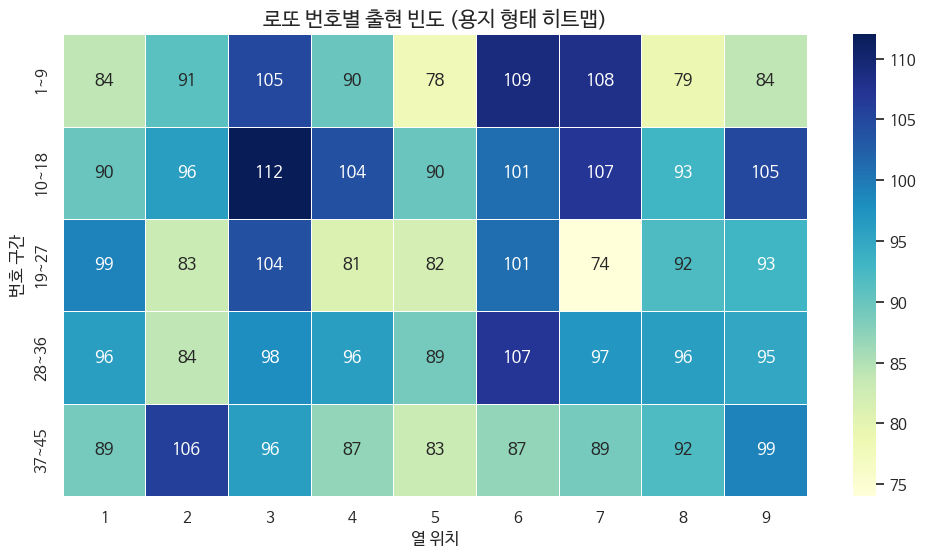

/tmp/ipython-input-2304793646.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_15.index, y=top_15.values, ax=axes[0], palette='viridis', order=top_15.index)
/tmp/ipython-input-2304793646.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=bottom_15.index, y=bottom_15.values, ax=axes[1], palette='rocket_r', order=bottom_15.index)


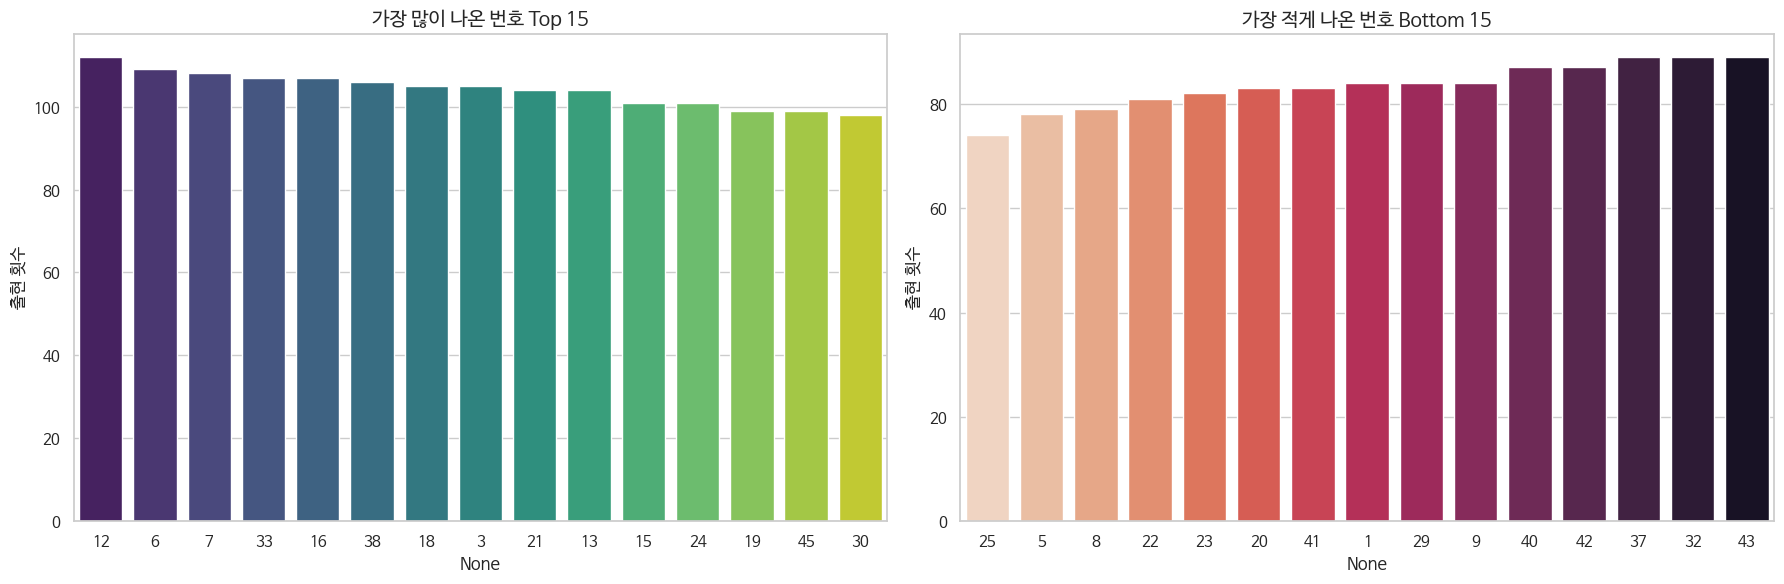

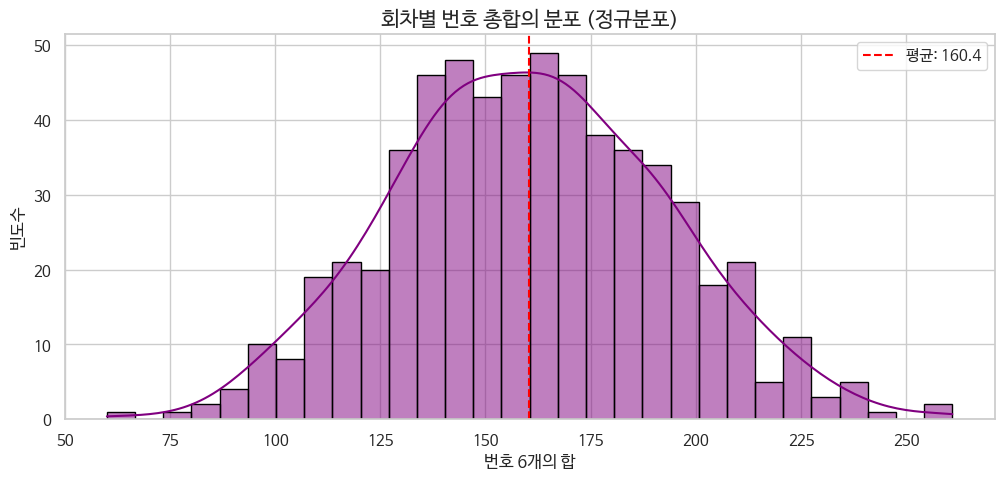

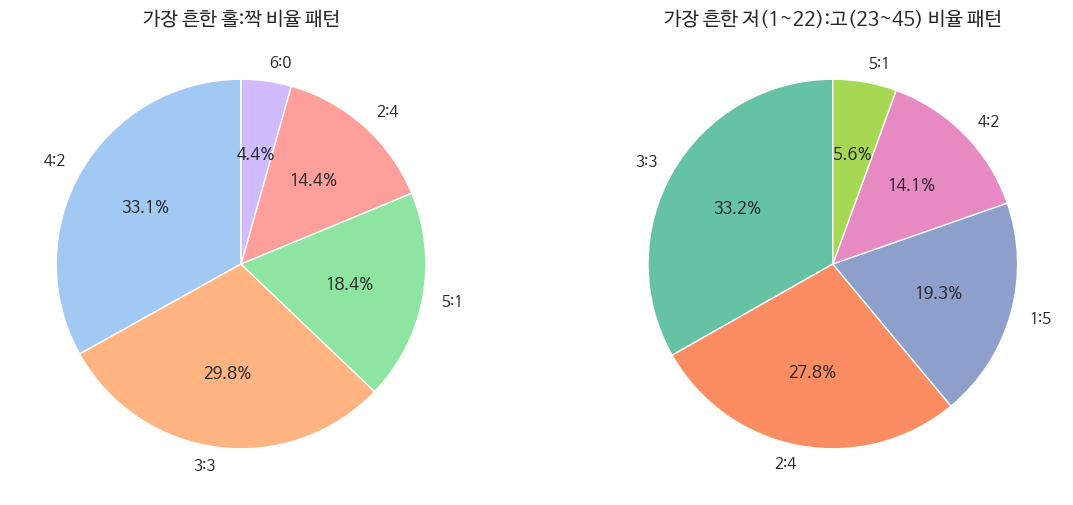


🎯 가장 많이 함께 나온 짝꿍 번호 Top 10


,"조합(번호1, 번호2)",출현 횟수
0,"(np.int64(21), np.int64(30))",25
1,"(np.int64(6), np.int64(18))",24
2,"(np.int64(3), np.int64(13))",24
3,"(np.int64(6), np.int64(17))",24
4,"(np.int64(7), np.int64(19))",24
5,"(np.int64(6), np.int64(28))",23
6,"(np.int64(6), np.int64(38))",23
7,"(np.int64(16), np.int64(21))",23
8,"(np.int64(7), np.int64(38))",23
9,"(np.int64(6), np.int64(21))",23


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from itertools import combinations
from collections import Counter
from google.colab import files

# ==========================================
# 0. 폰트 및 스타일 설정
# ==========================================
plt.rc('font', family='NanumBarunGothic') # 한글 폰트 설정
plt.rcParams['axes.unicode_minus'] = False # 마이너스 기호 깨짐 방지
sns.set(font='NanumBarunGothic', rc={"axes.unicode_minus":False}, style='whitegrid')

# ==========================================
# 1. 파일 업로드 및 데이터 처리
# ==========================================
print("엑셀 파일을 업로드해주세요.")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

df = pd.read_excel(filename)
lotto_cols = [1, 2, 3, 4, 5, 6,'보너스']
lotto_nums = df[lotto_cols]

# 전체 번호 리스트화
all_numbers = lotto_nums.values.flatten()
count_series = pd.Series(all_numbers).value_counts().sort_index()

# ==========================================
# 시각화 1: 번호별 출현 빈도 히트맵 (로또 용지 모양)
# ==========================================
# 1~45번을 5행 9열 (로또 용지 형태)로 변환
lotto_grid = np.zeros((5, 9))
for num in range(1, 46):
    row = (num - 1) // 9
    col = (num - 1) % 9
    # 해당 번호가 나온 횟수를 가져옴 (없으면 0)
    lotto_grid[row, col] = count_series.get(num, 0)

plt.figure(figsize=(12, 6))
sns.heatmap(lotto_grid, annot=True, fmt='.0f', cmap='YlGnBu', linewidths=.5,
            xticklabels=[str(i) for i in range(1, 10)],
            yticklabels=[f"{i*9+1}~{i*9+9}" for i in range(5)])
plt.title('로또 번호별 출현 빈도 (용지 형태 히트맵)', fontsize=15)
plt.xlabel('열 위치')
plt.ylabel('번호 구간')
plt.show()

# ==========================================
# 시각화 2: 가장 많이/적게 나온 번호 (Bar Chart)
# ==========================================
top_15 = count_series.sort_values(ascending=False).head(15)
bottom_15 = count_series.sort_values(ascending=True).head(15)

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 많이 나온 번호
sns.barplot(x=top_15.index, y=top_15.values, ax=axes[0], palette='viridis', order=top_15.index)
axes[0].set_title('가장 많이 나온 번호 Top 15', fontsize=14)
axes[0].set_ylabel('출현 횟수')

# 적게 나온 번호
sns.barplot(x=bottom_15.index, y=bottom_15.values, ax=axes[1], palette='rocket_r', order=bottom_15.index)
axes[1].set_title('가장 적게 나온 번호 Bottom 15', fontsize=14)
axes[1].set_ylabel('출현 횟수')

plt.tight_layout()
plt.show()

# ==========================================
# 시각화 3: 번호 총합 분포 (정규분포 형태 확인)
# ==========================================
df['sum'] = lotto_nums.sum(axis=1)

plt.figure(figsize=(12, 5))
sns.histplot(df['sum'], bins=30, kde=True, color='purple', edgecolor='black')
plt.axvline(df['sum'].mean(), color='red', linestyle='--', label=f"평균: {df['sum'].mean():.1f}")
plt.title('회차별 번호 총합의 분포 (정규분포)', fontsize=15)
plt.xlabel('번호 6개의 합')
plt.ylabel('빈도수')
plt.legend()
plt.show()

# ==========================================
# 시각화 4: 홀짝 비율 및 고저 비율 (Pie Chart)
# ==========================================
# 홀짝 계산
def get_odd_even_str(nums):
    odds = sum(1 for n in nums if n % 2 != 0)
    return f"{odds}:{6-odds}" # 홀:짝

# 고저 계산 (23 미만 = 저, 23 이상 = 고)
def get_high_low_str(nums):
    highs = sum(1 for n in nums if n >= 23)
    return f"{6-highs}:{highs}" # 저:고

df['odd_even'] = lotto_nums.apply(lambda x: get_odd_even_str(x.values), axis=1)
df['low_high'] = lotto_nums.apply(lambda x: get_high_low_str(x.values), axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 홀짝 파이차트
oe_counts = df['odd_even'].value_counts().head(5) # 상위 5개 패턴만
axes[0].pie(oe_counts, labels=oe_counts.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel'))
axes[0].set_title('가장 흔한 홀:짝 비율 패턴', fontsize=14)

# 고저 파이차트
lh_counts = df['low_high'].value_counts().head(5)
axes[1].pie(lh_counts, labels=lh_counts.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('Set2'))
axes[1].set_title('가장 흔한 저(1~22):고(23~45) 비율 패턴', fontsize=14)

plt.show()

# ==========================================
# 시각화 5: 많이 나온 조합 테이블 (데이터프레임 스타일링)
# ==========================================
# 2개 조합 계산
pair_combinations = []
for index, row in lotto_nums.iterrows():
    pair_combinations.extend(combinations(sorted(row.values), 2))

pair_counts = Counter(pair_combinations)
top_pairs = pair_counts.most_common(10)

# 데이터프레임 생성
pair_df = pd.DataFrame(top_pairs, columns=['조합(번호1, 번호2)', '출현 횟수'])

print("\n" + "="*50)
print("🎯 가장 많이 함께 나온 짝꿍 번호 Top 10")
print("="*50)

# 그라데이션 스타일 적용하여 출력
from IPython.display import display
styled_table = pair_df.style.background_gradient(cmap='Blues', subset=['출현 횟수']) \
                      .set_properties(**{'text-align': 'center'}) \
                      .set_table_styles([dict(selector='th', props=[('text-align', 'center')])])

display(styled_table)

In [2]:
import pandas as pd
import numpy as np
import random
from google.colab import files
from IPython.display import display, HTML

# ==========================================
# 1. 데이터 로드
# ==========================================
print("엑셀 파일을 업로드해주세요 (기존과 동일한 파일).")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

df = pd.read_excel(filename)
lotto_cols = [1, 2, 3, 4, 5, 6,'보너스']
lotto_nums = df[lotto_cols]

# ==========================================
# 2. 분석 엔진 설정 (가중치 및 과거 데이터)
# ==========================================
# 1) 번호별 가중치 계산 (많이 나온 번호가 뽑힐 확률을 높게 설정)
all_numbers = lotto_nums.values.flatten()
num_counts = pd.Series(all_numbers).value_counts().sort_index()

# 1~45번까지 없는 번호는 0으로 채움
weights = []
for i in range(1, 46):
    weights.append(num_counts.get(i, 0))

# 확률로 변환 (전체 빈도수 대비 해당 번호 빈도수)
total_count = sum(weights)
probs = [w / total_count for w in weights]

# 2) 과거 1등 당첨 조합 저장 (중복 제거용)
past_winning_sets = set([tuple(sorted(row)) for row in lotto_nums.values])

print("\n✅ 데이터 학습 완료!")
print(f" - 총 {len(df)}회차 데이터 분석됨")
print(f" - 번호별 출현 확률 계산 완료 (가중치 적용)")
print(f" - 과거 1등 조합 {len(past_winning_sets)}개 필터링 준비 완료")

엑셀 파일을 업로드해주세요 (기존과 동일한 파일).


Saving 로또번호분석.xlsx to 로또번호분석 (6).xlsx

✅ 데이터 학습 완료!
 - 총 603회차 데이터 분석됨
 - 번호별 출현 확률 계산 완료 (가중치 적용)
 - 과거 1등 조합 603개 필터링 준비 완료


In [6]:
# ==========================================
# 3. 필터링 규칙 함수 정의
# ==========================================
def is_valid_combination(nums):
    nums = sorted(nums)

    # 규칙 1: 과거 1등 번호와 똑같은지 확인
    if tuple(nums) in past_winning_sets:
        return False, "과거 1등 중복"

    # 규칙 2: 총합이 너무 적거나 많으면 제외 (통계적 정상 범위: 100 ~ 200)
    # (앞선 분석에서 평균이 약 140 전후였으므로 범위를 이렇게 잡음)
    total_sum = sum(nums)
    if not (100 <= total_sum <= 200):
        return False, "총합 범위 이탈"

    # 규칙 3: 홀짝 비율이 극단적인 경우 제외 (6:0 또는 0:6 제외)
    odds = sum(1 for n in nums if n % 2 != 0)
    if odds == 0 or odds == 6:
        return False, "극단적 홀짝 비율"

    # 규칙 4: 연속된 번호가 3개 이상인 경우 제외 (예: 1, 2, 3)
    consecutive_cnt = 0
    for i in range(len(nums) - 1):
        if nums[i] + 1 == nums[i+1]:
            consecutive_cnt += 1
            if consecutive_cnt >= 2: # 2번 연속되면 숫자는 3개가 연속된 것임
                return False, "3연속 번호 포함"
        else:
            consecutive_cnt = 0

    return True, "통과"

# ==========================================
# 4. 번호 생성기 함수
# ==========================================
def generate_lotto_numbers(n_games=5):
    recommendations = []

    print(f"🚀 {n_games}개의 최적 조합을 계산 중입니다...\n")

    while len(recommendations) < n_games:
        # 가중치를 적용하여 6개 번호 추출 (비복원 추출)
        candidate = np.random.choice(range(1, 46), size=6, replace=False, p=probs)
        candidate = sorted(candidate)

        # 필터링 검사
        valid, reason = is_valid_combination(candidate)

        if valid:
            # 홀짝 비율 및 합계 계산 (출력용)
            s_sum = sum(candidate)
            odds = sum(1 for n in candidate if n % 2 != 0)
            ratio = f"{odds}:{6-odds}"

            recommendations.append({
                '번호': candidate,
                '총합': s_sum,
                '홀:짝': ratio,
                '분석 결과': '✅ 추천'
            })

    return pd.DataFrame(recommendations)

# ==========================================
# 5. 실행 및 결과 출력
# ==========================================
# 몇 게임을 만들지 설정하세요
game_count = 20
result_df = generate_lotto_numbers(game_count)

# --- 시각화용 스타일 적용 ---
def color_balls(val):
    # 번호 리스트를 예쁜 공 모양 HTML로 변환
    html = ""
    for num in val:
        color = ""
        if num <= 10: color = "#fbc400" # 노랑
        elif num <= 20: color = "#69c8f2" # 파랑
        elif num <= 30: color = "#ff7272" # 빨강
        elif num <= 40: color = "#aaaaaa" # 회색
        else: color = "#b0d840" # 초록

        html += f'<span style="display:inline-block; width:30px; height:30px; line-height:30px; border-radius:50%; background-color:{color}; color:white; text-align:center; font-weight:bold; margin-right:5px; box-shadow: 1px 1px 2px gray;">{num}</span>'
    return html

# 데이터프레임 보여주기 (HTML 렌더링)
pd.set_option('display.max_colwidth', None)
final_view = result_df.copy()
final_view['번호'] = final_view['번호'].apply(color_balls)

display(HTML(f"<h3>🎰 AI 분석 기반 추천 번호 ({game_count}게임)</h3>"))
display(HTML(final_view.to_html(escape=False, index=False, justify='center')))

print("\n[알림] 위 번호는 과거 데이터 빈도(가중치)를 반영하고,")
print("통계적으로 확률이 낮은 조합(극단적 합계, 3연번 등)을 제거한 결과입니다.")

🚀 20개의 최적 조합을 계산 중입니다...



번호,총합,홀:짝,분석 결과
21217242735,117,3:3,✅ 추천
2522303640,135,1:5,✅ 추천
32124283544,155,3:3,✅ 추천
81113192145,117,5:1,✅ 추천
111930333844,175,3:3,✅ 추천
12021242945,140,4:2,✅ 추천
41319303745,148,4:2,✅ 추천
151822242837,144,2:4,✅ 추천
4712262735,111,3:3,✅ 추천
121724273036,146,2:4,✅ 추천



[알림] 위 번호는 과거 데이터 빈도(가중치)를 반영하고,
통계적으로 확률이 낮은 조합(극단적 합계, 3연번 등)을 제거한 결과입니다.
